In [4]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [5]:
class cricketState(TypedDict):
    score : int
    balls : int
    fours : int
    six : int
    sr : float
    br : int
    bpb : int

In [27]:
def calculate_sr(state : cricketState):
    runs = state['score']
    balls = state['balls']

    sr = runs / balls

    return {'sr' : sr}

def calculate_br(state : cricketState):
    fours = state['fours']
    six = state['six']

    runs = (4 * fours) + (6 * six)

    return {'br' : runs}


def calculate_bpb(state : cricketState):
    fours = state['fours']
    six = state['six']
    balls = state['balls']

    bpb = balls / (six + fours)

    return {'bpb' : bpb}



In [28]:
graph = StateGraph(cricketState)

graph.add_node('calculate_sr', calculate_sr)
graph.add_node('calculate_br', calculate_br)
graph.add_node('calculate_bpb', calculate_bpb)

graph.add_edge(START, 'calculate_sr')
graph.add_edge(START, 'calculate_br')
graph.add_edge(START, 'calculate_bpb')
graph.add_edge('calculate_sr', END)
graph.add_edge('calculate_br', END)
graph.add_edge('calculate_bpb', END)

workflow = graph.compile()

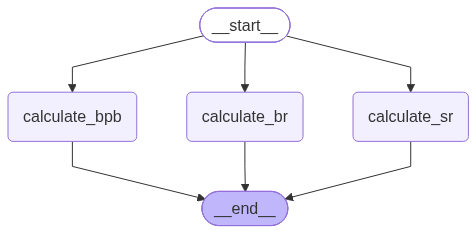

In [29]:
from  IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [30]:
workflow = graph.compile()

initial_state = {'score' : 154, 'balls' : 114, 'six' : 10, 'fours' : 16}

final_state = workflow.invoke(initial_state)
print(final_state)

{'score': 154, 'balls': 114, 'fours': 16, 'six': 10, 'sr': 1.3508771929824561, 'br': 124, 'bpb': 4.384615384615385}
